**TLDR**: Selects the feature type, number of PCA components k and ridge penalty λ by grouped 5-fold cross-validation on the training split (frames grouped in blocks of 100 consecutive frame numbers, so augmented copies and neighbouring frames never straddle a fold). The simplest model within one standard error of the best is chosen. A neural network (MLP) is compared as an alternative. The decision threshold is chosen on the validation split for 90 % recall, and the selected model is evaluated once on the test split, with bootstrap confidence intervals, an always-FAIL baseline, recall by defect type and an exposure-robustness check.

## Method
1. Grouped 5-fold CV on train over features ∈ {pixels, HOG}, k ∈ {10, 25, 50, 100, 200}, λ ∈ {1e-4, …, 1}. PCA is refitted inside each fold.
2. Select the smallest k within one standard error of the best CV AUC.
3. Compare an MLP (64 hidden units) tuned the same way.
4. Refit on the full training split; choose the threshold on validation for 90 % recall.
5. Evaluate once on test.

## Set-up

In [1]:
from google.colab import drive, userdata
drive.mount('/content/drive')

REPO_DIR = "/content/drive/MyDrive/MMA3001 Project/Pork-Tray-Inspection"
ZIP_PATH = "/content/drive/MyDrive/MMA3001/Pork Rasher Error-Packaging-.v4i.coco.zip"
%cd "{REPO_DIR}"

token = userdata.get("GITHUB_TOKEN")
PUSH_URL = f"https://{token}@github.com/chrixxv1/Pork-Tray-Inspection.git"

!mkdir -p /content/data
!unzip -oq "{ZIP_PATH}" -d /content/data
DATA_DIR = "/content/data"
CACHE_DIR = f"{REPO_DIR}/results/cache"

!pip install -q -e .
import sys
sys.path.insert(0, f"{REPO_DIR}/src")
!git branch

Mounted at /content/drive
/content/drive/MyDrive/MMA3001 Project/Pork-Tray-Inspection
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for porkqc (pyproject.toml) ... done
  feature/data-loader
  feature/experiment
  feature/features
  feature/logistic
  feature/pca
* main


## Branching

In [ ]:
# !git switch main
# !git pull {PUSH_URL} main
# !git switch -c feature/experiment


## Evaluation Module
Provides AUC, confusion-matrix metrics, threshold selection and bootstrap confidence intervals.

In [ ]:
%%writefile src/porkqc/evaluate.py
"""Evaluation metrics for the pass/fail decision, with bootstrap uncertainty.

Conventions: the positive class is FAIL (a defective tray), so

* **recall** is the fraction of defective trays that are caught, and
* **precision** is the fraction of rejected trays that really are defective.

On a production line a missed defect (false negative) reaches a customer,
while a false reject costs a manual re-check, so recall is the primary
operating constraint and the threshold is chosen to meet a target recall.
"""

from __future__ import annotations

from typing import Callable

import numpy as np
from scipy.stats import rankdata


def roc_auc(y: np.ndarray, score: np.ndarray) -> float:
    """Area under the ROC curve via the Mann-Whitney U statistic.

    AUC equals the probability that a randomly chosen FAIL image scores higher
    than a randomly chosen PASS image; ties count one half.

    Args:
        y: Labels in {0, 1}.
        score: Any score that increases with the probability of FAIL.

    Returns:
        AUC in [0, 1], or NaN if only one class is present.
    """
    y = np.asarray(y)
    score = np.asarray(score)
    pos, neg = score[y == 1], score[y == 0]
    if len(pos) == 0 or len(neg) == 0:
        return float("nan")
    # Midranks (average rank for tied scores) handle ties exactly.
    ranks = rankdata(np.concatenate([pos, neg]))
    u = ranks[: len(pos)].sum() - len(pos) * (len(pos) + 1) / 2
    return float(u / (len(pos) * len(neg)))


def binary_metrics(y: np.ndarray, prob: np.ndarray, threshold: float = 0.5) -> dict[str, float]:
    """Confusion-matrix metrics at a given decision threshold.

    Args:
        y: Labels in {0, 1}.
        prob: Predicted ``P(FAIL)``.
        threshold: Images with ``prob >= threshold`` are rejected (FAIL).

    Returns:
        Dictionary with accuracy, balanced accuracy, precision, recall,
        specificity, F1, AUC and the raw counts tp, fp, tn, fn.
    """
    y = np.asarray(y).astype(int)
    pred = (np.asarray(prob) >= threshold).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    recall = tp / (tp + fn) if tp + fn else float("nan")
    specificity = tn / (tn + fp) if tn + fp else float("nan")
    precision = tp / (tp + fp) if tp + fp else float("nan")
    f1 = 2 * precision * recall / (precision + recall) if tp else 0.0
    return {
        "accuracy": (tp + tn) / len(y),
        "balanced_accuracy": (recall + specificity) / 2,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1,
        "auc": roc_auc(y, np.asarray(prob)),
        "tp": tp, "fp": fp, "tn": tn, "fn": fn,
    }


def threshold_for_recall(y: np.ndarray, prob: np.ndarray, target_recall: float) -> float:
    """Highest threshold whose recall on ``(y, prob)`` is at least ``target_recall``.

    Intended for the validation split only; the chosen threshold is then
    applied unchanged to the test split.

    Args:
        y: Labels in {0, 1}.
        prob: Predicted ``P(FAIL)``.
        target_recall: Required recall in (0, 1].

    Returns:
        The decision threshold.

    Raises:
        ValueError: If ``target_recall`` is outside (0, 1].
    """
    if not 0 < target_recall <= 1:
        raise ValueError("target_recall must lie in (0, 1]")
    pos = np.sort(np.asarray(prob)[np.asarray(y) == 1])[::-1]
    k = int(np.ceil(target_recall * len(pos)))  # need the top-k positives above threshold
    return float(pos[k - 1])


def bootstrap_ci(y: np.ndarray, prob: np.ndarray,
                 metric: Callable[[np.ndarray, np.ndarray], float],
                 n_boot: int = 2000, level: float = 0.95, seed: int = 0) -> tuple[float, float]:
    """Percentile bootstrap confidence interval for a metric.

    Resamples test images with replacement. This captures sampling
    uncertainty from the small test set, but not correlation between nearby
    video frames, so the interval is likely optimistic.

    Args:
        y: Labels.
        prob: Predicted probabilities.
        metric: Function ``metric(y, prob) -> float``.
        n_boot: Number of bootstrap resamples.
        level: Confidence level.
        seed: Random seed.

    Returns:
        ``(lower, upper)`` bounds; resamples where the metric is NaN are skipped.
    """
    rng = np.random.default_rng(seed)
    n = len(y)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        v = metric(y[idx], prob[idx])
        if np.isfinite(v):
            vals.append(v)
    a = (1 - level) / 2
    return float(np.quantile(vals, a)), float(np.quantile(vals, 1 - a))

Overwriting src/porkqc/evaluate.py


## Grouped Cross-validation Module

In [ ]:
%%writefile src/porkqc/selection.py
"""Grouped cross-validation for model selection.

The training images are frames from conveyor video, and each frame appears
three times (exposure-augmented copies). A random K-fold split would put copies
of the same frame - and neighbouring frames showing the same tray - on both
sides of a fold, so validation scores would be optimistic (target leakage).

Following the grouped-split practice for correlated records, frames are
grouped into blocks of consecutive frame numbers and whole blocks are assigned
to folds (``sklearn.model_selection.GroupKFold``). Augmented copies share a
frame number, so they always fall in the same group. Different videos reuse
frame numbers, so a block may contain frames from several videos; that only
makes the grouping more conservative.
"""

from __future__ import annotations

import re
from typing import Callable

import numpy as np
from sklearn.model_selection import GroupKFold

from .data import ImageRecord


def frame_number(record: ImageRecord) -> int:
    """Frame number parsed from the source name, e.g. ``frame_with_red_8214.jpg`` -> 8214.

    Args:
        record: Image record.

    Returns:
        The frame number.

    Raises:
        ValueError: If the source name contains no number.
    """
    m = re.search(r"(\d+)(?!.*\d)", record.source_name)
    if m is None:
        raise ValueError(f"No frame number in {record.source_name!r}")
    return int(m.group(1))


def frame_block_groups(records: list[ImageRecord], block: int = 100) -> np.ndarray:
    """Group label for each record: its frame number divided by ``block``.

    Args:
        records: Image records.
        block: Number of consecutive frame numbers per group.

    Returns:
        Integer array of shape ``(len(records),)``.

    Raises:
        ValueError: If ``block`` is less than 1.
    """
    if block < 1:
        raise ValueError("block must be at least 1")
    return np.array([frame_number(r) // block for r in records])


def grouped_cv_scores(X: np.ndarray, y: np.ndarray, groups: np.ndarray,
                      fit_predict: Callable[[np.ndarray, np.ndarray, np.ndarray], np.ndarray],
                      score: Callable[[np.ndarray, np.ndarray], float],
                      n_splits: int = 5) -> np.ndarray:
    """Score a model with grouped K-fold cross-validation.

    Args:
        X: Features, shape ``(n, d)``.
        y: Labels, shape ``(n,)``.
        groups: Group label per row; no group is split across folds.
        fit_predict: ``fit_predict(X_train, y_train, X_test) -> scores`` fits a
            model on the training rows and returns scores for the test rows.
        score: Metric ``score(y_true, scores) -> float``.
        n_splits: Number of folds.

    Returns:
        Array of ``n_splits`` fold scores.
    """
    out = []
    for tr, te in GroupKFold(n_splits=n_splits).split(X, y, groups):
        out.append(score(y[te], fit_predict(X[tr], y[tr], X[te])))
    return np.array(out)

Writing src/porkqc/selection.py


## Tests for Evaluation

In [ ]:
%%writefile tests/test_evaluate.py
"""Tests of the evaluation metrics against hand calculations and scikit-learn."""

import numpy as np
import pytest
from sklearn.metrics import roc_auc_score

from porkqc.evaluate import binary_metrics, bootstrap_ci, roc_auc, threshold_for_recall


def test_auc_limits_and_ties():
    y = np.array([0, 0, 1, 1])
    assert roc_auc(y, np.array([0.1, 0.2, 0.8, 0.9])) == 1.0
    assert roc_auc(y, np.array([0.9, 0.8, 0.2, 0.1])) == 0.0
    assert roc_auc(y, np.full(4, 0.5)) == 0.5
    assert np.isnan(roc_auc(np.ones(3), np.ones(3)))


def test_auc_matches_scikit_learn():
    rng = np.random.default_rng(0)
    y = rng.integers(0, 2, 200)
    s = rng.random(200).round(2)  # rounding creates ties
    assert np.isclose(roc_auc(y, s), roc_auc_score(y, s))


def test_binary_metrics_hand_example():
    y = np.array([1, 1, 1, 0, 0])
    p = np.array([0.9, 0.6, 0.2, 0.7, 0.1])
    m = binary_metrics(y, p, threshold=0.5)
    assert (m["tp"], m["fn"], m["fp"], m["tn"]) == (2, 1, 1, 1)
    assert np.isclose(m["recall"], 2 / 3) and np.isclose(m["precision"], 2 / 3)


def test_threshold_for_recall_meets_target():
    rng = np.random.default_rng(1)
    y = rng.integers(0, 2, 100)
    p = rng.random(100)
    for target in (0.5, 0.9, 1.0):
        t = threshold_for_recall(y, p, target)
        assert binary_metrics(y, p, t)["recall"] >= target
    with pytest.raises(ValueError):
        threshold_for_recall(y, p, 0.0)


def test_bootstrap_interval_contains_point_estimate():
    rng = np.random.default_rng(2)
    y = rng.integers(0, 2, 80)
    p = np.clip(y * 0.4 + rng.random(80) * 0.6, 0, 1)
    lo, hi = bootstrap_ci(y, p, roc_auc, n_boot=500)
    assert lo <= roc_auc(y, p) <= hi

Overwriting tests/test_evaluate.py


## Tests for Group-Crossed Validation
The last test is the important one. It shows that with duplicated images, like your augmented copies, random folds reward memorisation and give a misleadingly high score, while grouped folds give the honest chance-level result.

In [ ]:
%%writefile tests/test_selection.py
"""Tests of frame grouping and grouped cross-validation."""

from pathlib import Path

import numpy as np
import pytest

from porkqc.data import ImageRecord
from porkqc.evaluate import roc_auc
from porkqc.selection import frame_block_groups, frame_number, grouped_cv_scores


def _rec(name):
    return ImageRecord(Path(name), name, 0, ())


def test_frame_number_and_blocks():
    recs = [_rec("frame_with_red_8214.jpg"), _rec("frame_with_red_8299.jpg"),
            _rec("frame_with_red_8300.jpg"), _rec("frame_with_red_3.jpg")]
    assert frame_number(recs[0]) == 8214
    assert frame_block_groups(recs, block=100).tolist() == [82, 82, 83, 0]


def test_bad_names_and_block_rejected():
    with pytest.raises(ValueError):
        frame_number(_rec("no_number_here.jpg"))
    with pytest.raises(ValueError):
        frame_block_groups([_rec("frame_1.jpg")], block=0)


def test_no_group_is_split_across_folds():
    rng = np.random.default_rng(0)
    n = 300
    groups = np.repeat(np.arange(30), 10)
    X, y = rng.standard_normal((n, 3)), rng.integers(0, 2, n).astype(float)
    seen = []

    def fit_predict(Xtr, ytr, Xte):
        seen.append(len(Xte))
        return Xte[:, 0]

    scores = grouped_cv_scores(X, y, groups, fit_predict, roc_auc, n_splits=5)
    assert len(scores) == 5 and sum(seen) == n

    from sklearn.model_selection import GroupKFold
    for tr, te in GroupKFold(5).split(X, y, groups):
        assert not set(groups[tr]) & set(groups[te])


def test_grouping_removes_leakage_from_duplicates():
    """With duplicated rows, random folds reward memorisation; grouped folds do not."""
    from sklearn.model_selection import KFold
    from sklearn.neighbors import KNeighborsClassifier

    rng = np.random.default_rng(1)
    X0 = rng.standard_normal((100, 5))
    y0 = rng.integers(0, 2, 100).astype(float)  # labels are pure noise
    X, y = np.repeat(X0, 3, axis=0), np.repeat(y0, 3)  # three copies, like augmentation
    groups = np.repeat(np.arange(100), 3)

    def fit_predict(Xtr, ytr, Xte):
        return KNeighborsClassifier(1).fit(Xtr, ytr).predict_proba(Xte)[:, 1]

    grouped = grouped_cv_scores(X, y, groups, fit_predict, roc_auc).mean()
    random = np.mean([roc_auc(y[te], fit_predict(X[tr], y[tr], X[te]))
                      for tr, te in KFold(5, shuffle=True, random_state=0).split(X)])
    assert random > 0.9          # leakage: copies of the test row are in training
    assert abs(grouped - 0.5) < 0.15   # honest: noise labels give chance-level AUC

Overwriting tests/test_selection.py


## Run Tests

In [ ]:
!pytest -q

.....................................................                    [100%]
53 passed in 4.50s


## Load Features and Build Frame Groups

In [2]:
import json, time, warnings
import numpy as np
import matplotlib.pyplot as plt
from porkqc.data import load_dataset
from porkqc.features import extract
from porkqc.selection import frame_block_groups

ds = load_dataset(DATA_DIR)
feats = {m: {s: extract(ds[s], m, cache_dir=CACHE_DIR) for s in ("train", "valid", "test")}
         for m in ("pixels", "hog")}
groups = frame_block_groups(ds["train"], block=100)
print("Training images:", len(groups), "| groups (blocks of 100 frame numbers):", len(np.unique(groups)))

Training images: 3349 | groups (blocks of 100 frame numbers): 106


## Grouped Cross-Validation Over Features, k and λ

Grouped CV finished in 116 s

Mean CV AUC, pixels features (rows: k, columns: λ = [0.0001, 0.001, 0.01, 0.1, 1.0])
k =  10: [0.654, 0.654, 0.654, 0.653, 0.652]
k =  25: [0.685, 0.685, 0.684, 0.68, 0.677]
k =  50: [0.695, 0.696, 0.696, 0.693, 0.691]
k = 100: [0.713, 0.715, 0.715, 0.705, 0.698]
k = 200: [0.646, 0.657, 0.677, 0.682, 0.679]

Mean CV AUC, hog features (rows: k, columns: λ = [0.0001, 0.001, 0.01, 0.1, 1.0])
k =  10: [0.647, 0.647, 0.647, 0.646, 0.646]
k =  25: [0.687, 0.687, 0.686, 0.683, 0.681]
k =  50: [0.722, 0.722, 0.722, 0.72, 0.719]
k = 100: [0.722, 0.722, 0.721, 0.72, 0.719]
k = 200: [0.729, 0.73, 0.732, 0.73, 0.727]


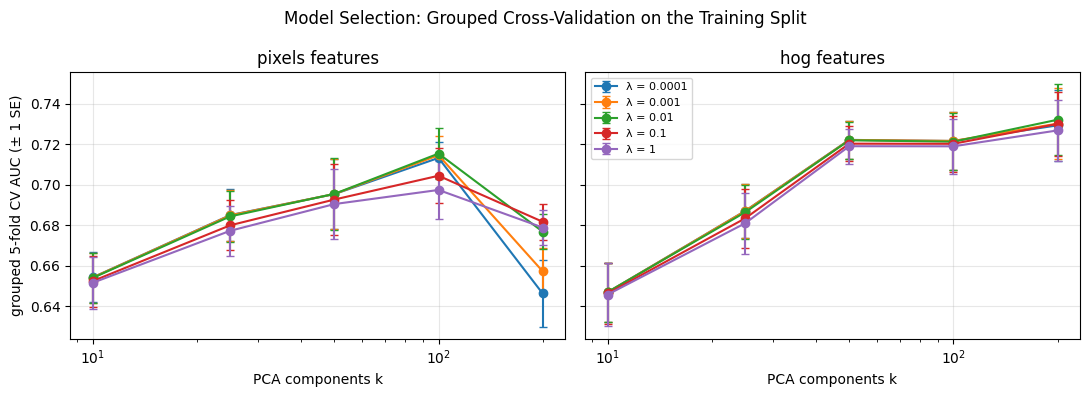

In [ ]:
from sklearn.model_selection import GroupKFold
from porkqc.pca import PCA
from porkqc.logistic import LogisticRegression
from porkqc.evaluate import roc_auc

K_GRID = [10, 25, 50, 100, 200]
L2_GRID = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
N_FOLDS = 5

t0 = time.perf_counter()
cv_rows = []
for method in ("pixels", "hog"):
    X, y = feats[method]["train"]
    fold_aucs = {(k, l2): [] for k in K_GRID for l2 in L2_GRID}
    for tr, te in GroupKFold(N_FOLDS).split(X, y, groups):
        # PCA is refitted inside every fold, on the fold's training rows only.
        pca = PCA(max(K_GRID), solver="randomized").fit(X[tr])
        Z_tr, Z_te = pca.transform(X[tr]), pca.transform(X[te])
        for k in K_GRID:
            for l2 in L2_GRID:
                clf = LogisticRegression(l2=l2).fit(Z_tr[:, :k], y[tr])
                fold_aucs[(k, l2)].append(roc_auc(y[te], clf.predict_proba(Z_te[:, :k])))
    for (k, l2), aucs in fold_aucs.items():
        cv_rows.append({"features": method, "k": k, "l2": l2,
                        "cv_auc": float(np.mean(aucs)), "cv_sd": float(np.std(aucs))})
print(f"Grouped CV finished in {time.perf_counter() - t0:.0f} s")

for method in ("pixels", "hog"):
    print(f"\nMean CV AUC, {method} features (rows: k, columns: λ = {L2_GRID})")
    for k in K_GRID:
        print(f"k = {k:3d}:", [round(r["cv_auc"], 3) for r in cv_rows if r["features"] == method and r["k"] == k])

import os
os.makedirs("results/figures", exist_ok=True)
LABELS = {"pixels": "Pixel", "hog": "HOG"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, method in zip(axes, ("pixels", "hog")):
    for l2 in L2_GRID:
        r = [x for x in cv_rows if x["features"] == method and x["l2"] == l2]
        ax.errorbar([x["k"] for x in r], [x["cv_auc"] for x in r],
                    yerr=[x["cv_sd"] / np.sqrt(N_FOLDS) for x in r], marker="o", capsize=3, label=f"λ = {l2:g}")
    ax.set(xscale="log", xlabel="PCA components k", title=f"{LABELS[method]} features")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("grouped 5-fold CV AUC (± 1 SE)")
axes[1].legend(fontsize=8)
fig.suptitle("Model Selection: Grouped Cross-Validation on the Training Split")
plt.tight_layout()
fig.savefig("results/figures/6_cv_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

## Select Model (One-Standard-Error-Rule)

In [ ]:
best = max(cv_rows, key=lambda r: r["cv_auc"])
one_se = best["cv_sd"] / np.sqrt(N_FOLDS)
within = [r for r in cv_rows if r["features"] == best["features"] and r["cv_auc"] >= best["cv_auc"] - one_se]
k_sel = min(r["k"] for r in within)
selected = max((r for r in within if r["k"] == k_sel), key=lambda r: r["cv_auc"])

print(f"Best: {best['features']}, k = {best['k']}, λ = {best['l2']:g}, CV AUC = {best['cv_auc']:.3f} ± {one_se:.3f} (1 SE)")
print(f"Selected (smallest k within 1 SE): {selected['features']}, k = {selected['k']}, "
      f"λ = {selected['l2']:g}, CV AUC = {selected['cv_auc']:.3f}")
FEATURES, K, L2 = selected["features"], selected["k"], selected["l2"]

Best: hog, k = 200, λ = 0.01, CV AUC = 0.732 ± 0.017 (1 SE)
Selected (smallest k within 1 SE): hog, k = 50, λ = 0.0001, CV AUC = 0.722


## Alternative Model: Neural Network (MLP)

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

X, y = feats[FEATURES]["train"]
t0 = time.perf_counter()
mlp_folds = {}
for tr, te in GroupKFold(N_FOLDS).split(X, y, groups):
    pca = PCA(100, solver="randomized").fit(X[tr])
    Z_tr, Z_te = pca.transform(X[tr]), pca.transform(X[te])
    for k in (25, 50, 100):
        for alpha in (1e-4, 1e-2, 1.0):
            net = MLPClassifier(hidden_layer_sizes=(64,), alpha=alpha, max_iter=300, random_state=0)
            net.fit(Z_tr[:, :k], y[tr])
            mlp_folds.setdefault((k, alpha), []).append(roc_auc(y[te], net.predict_proba(Z_te[:, :k])[:, 1]))
print(f"MLP grouped CV finished in {time.perf_counter() - t0:.0f} s")
for (k, alpha), aucs in mlp_folds.items():
    print(f"k = {k:3d}, alpha = {alpha:g}: CV AUC = {np.mean(aucs):.3f} ± {np.std(aucs) / np.sqrt(N_FOLDS):.3f}")
(mlp_k, mlp_alpha), mlp_aucs = max(mlp_folds.items(), key=lambda kv: np.mean(kv[1]))
print(f"\nBest MLP: k = {mlp_k}, alpha = {mlp_alpha:g}, CV AUC = {np.mean(mlp_aucs):.3f}"
      f"  vs logistic regression {selected['cv_auc']:.3f}")

MLP grouped CV finished in 218 s
k =  25, alpha = 0.0001: CV AUC = 0.653 ± 0.011
k =  25, alpha = 0.01: CV AUC = 0.656 ± 0.012
k =  25, alpha = 1: CV AUC = 0.680 ± 0.011
k =  50, alpha = 0.0001: CV AUC = 0.705 ± 0.010
k =  50, alpha = 0.01: CV AUC = 0.706 ± 0.010
k =  50, alpha = 1: CV AUC = 0.717 ± 0.011
k = 100, alpha = 0.0001: CV AUC = 0.703 ± 0.014
k = 100, alpha = 0.01: CV AUC = 0.704 ± 0.014
k = 100, alpha = 1: CV AUC = 0.712 ± 0.015

Best MLP: k = 50, alpha = 1, CV AUC = 0.717  vs logistic regression 0.722


## Final Model & Validation Threshold

In [ ]:
from porkqc.evaluate import binary_metrics, threshold_for_recall

TARGET_RECALL = 0.9
(X_tr, y_tr), (X_va, y_va), (X_te, y_te) = (feats[FEATURES][s] for s in ("train", "valid", "test"))
pca = PCA(K).fit(X_tr)   # exact (full) SVD for the final model
Z_tr, Z_va, Z_te = pca.transform(X_tr), pca.transform(X_va), pca.transform(X_te)
model = LogisticRegression(l2=L2, tol=1e-10).fit(Z_tr, y_tr)

p_va = model.predict_proba(Z_va)
threshold = threshold_for_recall(y_va, p_va, TARGET_RECALL)
m_va = binary_metrics(y_va, p_va, threshold)
print(f"Validation AUC = {m_va['auc']:.3f}")
print(f"Threshold for {TARGET_RECALL:.0%} validation recall = {threshold:.3f} "
      f"(validation recall {m_va['recall']:.2f}, specificity {m_va['specificity']:.2f})")

Validation AUC = 0.784
Threshold for 90% validation recall = 0.736 (validation recall 0.91, specificity 0.43)


## Test Evaluation

In [ ]:
from porkqc.evaluate import bootstrap_ci

p_te = model.predict_proba(Z_te)
test = binary_metrics(y_te, p_te, threshold)
auc_ci = bootstrap_ci(y_te, p_te, roc_auc)
recall_ci = bootstrap_ci(y_te, p_te, lambda y, p: binary_metrics(y, p, threshold)["recall"])
baseline = binary_metrics(y_te, np.ones_like(y_te), 0.5)   # always FAIL

print(f"{'':22s}{'model':>10s}{'always FAIL':>14s}")
for name in ("auc", "recall", "specificity", "precision", "balanced_accuracy", "accuracy"):
    print(f"{name:22s}{test[name]:10.3f}{baseline[name]:14.3f}")
print(f"\nAUC 95 % CI {auc_ci[0]:.2f}–{auc_ci[1]:.2f}, recall 95 % CI {recall_ci[0]:.2f}–{recall_ci[1]:.2f}")
print(f"Confusion: TP {test['tp']}, FN {test['fn']}, FP {test['fp']}, TN {test['tn']}")

recall_by_defect = {}
for rec, p in zip(ds["test"], p_te):
    for c in rec.categories:
        recall_by_defect.setdefault(c, []).append(p >= threshold)
print("\nRecall by defect type:")
for c, hits in sorted(recall_by_defect.items()):
    print(f"  {c:16s} n = {len(hits):2d}, recall = {np.mean(hits):.2f}")

                           model   always FAIL
auc                        0.833         0.500
recall                     0.735         1.000
specificity                0.833         0.000
precision                  0.962         0.850
balanced_accuracy          0.784         0.500
accuracy                   0.750         0.850

AUC 95 % CI 0.65–0.95, recall 95 % CI 0.63–0.84
Confusion: TP 50, FN 18, FP 2, TN 10

Recall by defect type:
  loose-meat       n =  2, recall = 0.50
  packaging-error  n = 16, recall = 0.62
  twisted-meat     n =  4, recall = 0.00
  unsealed         n = 49, recall = 0.84


## Neural Network on Test (Three Seeds)

In [ ]:
pca_mlp = pca if mlp_k == K else PCA(mlp_k).fit(X_tr)
Zm_tr, Zm_te = pca_mlp.transform(X_tr), pca_mlp.transform(X_te)
mlp_test = []
for seed in (0, 1, 2):
    net = MLPClassifier(hidden_layer_sizes=(64,), alpha=mlp_alpha, max_iter=300, random_state=seed)
    net.fit(Zm_tr, y_tr)
    mlp_test.append(roc_auc(y_te, net.predict_proba(Zm_te)[:, 1]))
print("MLP test AUC for seeds 0, 1, 2:", [round(a, 3) for a in mlp_test],
      f"(spread {max(mlp_test) - min(mlp_test):.3f}); logistic regression: {test['auc']:.3f}")

MLP test AUC for seeds 0, 1, 2: [0.815, 0.771, 0.749] (spread 0.066); logistic regression: 0.833


## Robustness to Exposure

In [ ]:
robustness = {}
for e in (0.7, 0.85, 1.0, 1.15, 1.3):
    X_e, _ = extract(ds["test"], FEATURES, exposure=e, cache_dir=CACHE_DIR)
    m_e = binary_metrics(y_te, model.predict_proba(pca.transform(X_e)), threshold)
    robustness[e] = {"auc": m_e["auc"], "recall": m_e["recall"]}
    print(f"exposure × {e:4.2f}: AUC {m_e['auc']:.3f}, recall {m_e['recall']:.3f}")

exposure × 0.70: AUC 0.830, recall 0.779
exposure × 0.85: AUC 0.836, recall 0.735
exposure × 1.00: AUC 0.833, recall 0.735
exposure × 1.15: AUC 0.835, recall 0.750
exposure × 1.30: AUC 0.831, recall 0.735


## Save Results

In [ ]:
results = {
    "selected": {"features": FEATURES, "k": K, "l2": L2, "cv_auc": selected["cv_auc"]},
    "threshold": threshold, "target_recall": TARGET_RECALL,
    "valid": m_va, "test": test, "test_auc_ci95": auc_ci, "test_recall_ci95": recall_ci,
    "baseline_always_fail": baseline,
    "recall_by_defect": {c: {"n": len(h), "recall": float(np.mean(h))} for c, h in recall_by_defect.items()},
    "mlp": {"k": mlp_k, "alpha": mlp_alpha, "cv_auc": float(np.mean(mlp_aucs)), "test_auc_seeds": mlp_test},
    "exposure_robustness": robustness, "cv_grid": cv_rows,
}
with open("results/6_metrics.json", "w") as f:
    json.dump(results, f, indent=2, default=float)
print("Saved results/6_metrics.json")

Saved results/6_metrics.json


## Documentation

In [ ]:
%%writefile docs/6_experiment.md
# Model selection and final evaluation

Notebook: `notebooks/6_experiment.ipynb`. Code: `src/porkqc/evaluate.py`, `src/porkqc/selection.py`.
Full results: `results/6_metrics.json`.

## Protocol

1. Grouped 5-fold cross-validation on the training split. Frames are grouped in
   blocks of 100 consecutive frame numbers (106 groups), so augmented copies and
   neighbouring frames of the same tray never fall on both sides of a fold.
   PCA is refitted inside each fold.
2. Grid: features ∈ {pixels, HOG}, k ∈ {10, 25, 50, 100, 200}, λ ∈ {1e-4, ..., 1}.
3. Selection: the smallest k within one standard error of the best CV AUC.
4. Alternative: an MLP with 64 hidden units, tuned the same way.
5. Threshold chosen on the validation split for 90 % recall; single test evaluation.

![Grouped CV AUC against k](../results/figures/6_cv_sensitivity.png)

## Model selection

- HOG outperformed pixel features for k ≥ 50; λ had little effect.
- Best CV AUC: HOG, k = 200, λ = 0.01 (0.732 ± 0.017). Selected: HOG, k = 50,
  λ = 1e-4 (0.722), which is within one standard error and four times smaller.
- MLP best CV AUC: 0.717 (k = 50, α = 1), no better than logistic regression.

## Test results (80 images: 68 FAIL, 12 PASS)

Threshold 0.736 (from validation, 90 % recall target).

| Metric | Model | Always-FAIL baseline |
|---|---|---|
| AUC | 0.833 (95 % CI 0.65–0.95) | 0.500 |
| Recall | 0.735 (95 % CI 0.63–0.84) | 1.000 |
| Specificity | 0.833 (10/12) | 0.000 |
| Precision | 0.962 | 0.850 |
| Balanced accuracy | 0.784 | 0.500 |
| Accuracy | 0.750 | 0.850 |

Recall by defect type: unsealed 0.84 (n = 49), packaging-error 0.62 (n = 16),
loose meat 0.50 (n = 2), twisted meat 0.00 (n = 4).

MLP test AUC over three random seeds: 0.815, 0.771, 0.749.

Exposure robustness (×0.7 to ×1.3): test AUC 0.830–0.836.

## Findings

- **Accuracy is misleading**: the always-FAIL baseline scores higher accuracy
  (0.85) than the model (0.75) because 85 % of test images are FAIL.
- **The threshold did not transfer**: 90 % recall on validation became 74 % on
  test. With 106 FAIL validation images, the threshold estimate is noisy.
- **Estimates disagree across splits**: CV AUC 0.722, validation 0.784, test
  0.833. The grouped CV estimate uses the most images and controls leakage, so
  it is the most trustworthy; the higher test AUC may reflect neighbouring
  frames of the same trays appearing in both train and test, plus small-sample
  noise (the 95 % CI is 0.65–0.95).
- **Twisted meat is never caught**, and packaging-error recall is low; these
  defects are small or subtle and are not captured by 50 PCA components.
- **The MLP is less repeatable**: its test AUC varies by 0.066 with the random
  seed alone, whereas logistic regression has a unique solution.
- **Robust to exposure** well beyond the ±10 % training augmentation.

Writing docs/6_experiment.md


## AI Usage Log

In [ ]:
# Already appended - do not rerun, or the row is added twice.
# %%writefile -a AI_USE_LOG.md
# | 2026-10-27 | Claude | Wrote the code and summary: src/porkqc/evaluate.py, src/porkqc/selection.py (grouped cross-validation following the Week 5 grouped-split approach), the model-selection, MLP-comparison, test-evaluation and robustness analyses, and 9 tests | Ran the full experiment on my data and checked the outputs against the expected values; ran all tests (53 passed); asked Claude to explain parts I did not understand |


## Commit


In [3]:
!git switch main
!git add notebooks/ docs/ results/ AI_USE_LOG.md
!git commit -m "Update notebook outputs and Phase 6 figure titles"
!git pull --no-rebase --no-edit {PUSH_URL} main
!git push {PUSH_URL} main
!git log --oneline --graph -8


M	AI_USE_LOG.md
M	notebooks/0_setup.ipynb
M	notebooks/1_exploring_data.ipynb
M	notebooks/3_features.ipynb
M	notebooks/4_pca.ipynb
M	notebooks/5_logistic.ipynb
M	notebooks/6_experiment.ipynb
Already on 'main'
Your branch is ahead of 'origin/main' by 22 commits.
  (use "git push" to publish your local commits)
[main 8e5ee0d] Update notebook outputs and Phase 6 figure titles
 8 files changed, 8 insertions(+), 6 deletions(-)
 create mode 100644 notebooks/6_experiment (1).ipynb
From https://github.com/chrixxv1/Pork-Tray-Inspection
 * branch            main       -> FETCH_HEAD
Merge made by the 'ort' strategy.
 docs/5_logistic_regression.md | 2 +-
 1 file changed, 1 insertion(+), 1 deletion(-)
Enumerating objects: 60, done.
Counting objects: 100% (50/50), done.
Delta compression using up to 2 threads
Compressing objects: 100% (34/34), done.
Writing objects: 100% (36/36), 307.93 KiB | 3.24 MiB/s, done.
Total 36 (delta 19), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (19/1